# Module 09 · PCB và ESD (EASA M04 SM02)
Phần tính toán dùng vật lý cơ bản để minh hoạ; không nằm trong văn bản EASA.

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Điện trở và sụt áp của đường dẫn đồng

L=100 mm w=0.25 mm t=35 um: R = 192.0 mOhm; drop at 1 A = 192.0 mV
L=100 mm w=1.0 mm t=35 um: R = 48.0 mOhm; drop at 1 A = 48.0 mV
L=100 mm w=0.25 mm t=70 um: R = 96.0 mOhm; drop at 1 A = 96.0 mV


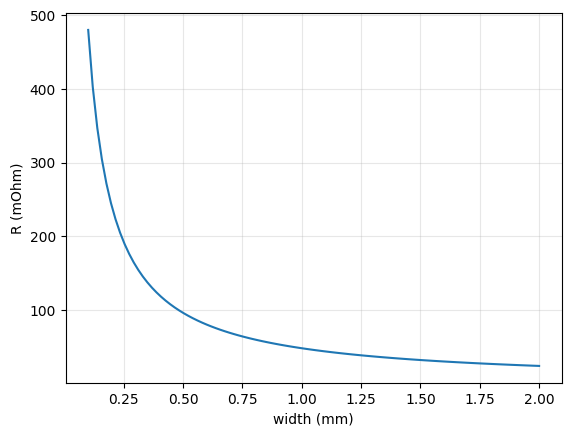

In [2]:
rho = 1.68e-8
def R(L_mm, w_mm, t_um): return rho*L_mm*1e-3/(w_mm*1e-3*t_um*1e-6)
for L, w, t in [(100, 0.25, 35), (100, 1.0, 35), (100, 0.25, 70)]:
    r = R(L, w, t); print(f"L={L} mm w={w} mm t={t} um: R = {r*1e3:.1f} mOhm; drop at 1 A = {r*1e3:.1f} mV")
w = np.linspace(0.1, 2, 100); plt.plot(w, R(100, w, 35)*1e3); plt.xlabel("width (mm)"); plt.ylabel("R (mOhm)"); plt.grid(alpha=.3); plt.show()

**Nhận xét:** đường 100 mm × 0,25 mm × 35 μm có R ≈ 192 mΩ (sụt 192 mV ở 1 A); tăng chiều rộng hoặc độ dày gấp đôi giảm R một nửa — R tỉ lệ nghịch với tiết diện.

## 2. Điện dung giữa hai lớp (ghép ký sinh)

In [3]:
eps0 = 8.854e-12
for er, A, d in [(4.5, 1.0, 0.2), (4.5, 4.0, 0.1), (4.5, 1.0, 0.4)]:
    C = eps0*er*A*1e-4/(d*1e-3); print(f"er={er} A={A} cm2 d={d} mm: C = {C*1e12:.2f} pF")
C = eps0*4.5*1e-4/0.2e-3
for f in (1e6, 100e6): print(f"f = {f/1e6:.0f} MHz: |Z| = {1/(2*np.pi*f*C):.0f} ohm")

er=4.5 A=1.0 cm2 d=0.2 mm: C = 19.92 pF
er=4.5 A=4.0 cm2 d=0.1 mm: C = 159.37 pF
er=4.5 A=1.0 cm2 d=0.4 mm: C = 9.96 pF
f = 1 MHz: |Z| = 7989 ohm
f = 100 MHz: |Z| = 80 ohm


**Nhận xét:** 1 cm² FR-4 dày 0,2 mm cho khoảng 19,9 pF; ở 100 MHz trở kháng chỉ còn khoảng 80 Ω (ở 1 MHz khoảng 8 kΩ) nên tín hiệu cao tần ghép sang lớp bên cạnh — đúng cảnh báo của EASA về ghép ký sinh.

## 3. Xả tĩnh điện: mô hình cơ thể người (minh hoạ)

   250 V: stored energy =     3.12 uJ, peak current =   0.17 A
   380 V: stored energy =     7.22 uJ, peak current =   0.25 A
  1500 V: stored energy =   112.50 uJ, peak current =   1.00 A
  3000 V: stored energy =   450.00 uJ, peak current =   2.00 A
  7000 V: stored energy =  2450.00 uJ, peak current =   4.67 A
 35000 V: stored energy = 61250.00 uJ, peak current =  23.33 A


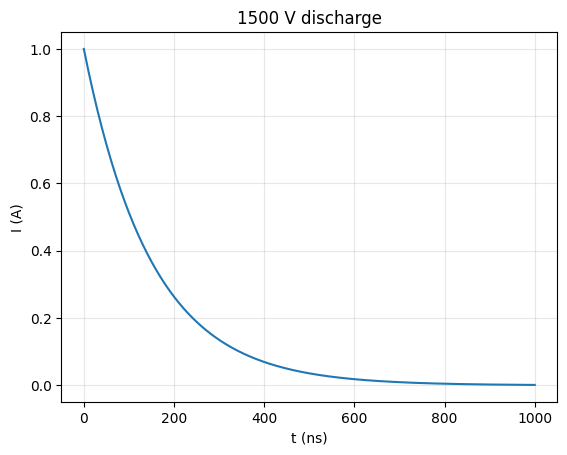

time constant = 150.0 ns


In [4]:
C, Rb = 100e-12, 1500.0     # common illustrative HBM values (not from EASA)
for V in (250, 380, 1500, 3000, 7000, 35000):
    print(f"{V:>6} V: stored energy = {0.5*C*V**2*1e6:8.2f} uJ, peak current = {V/Rb:6.2f} A")
t = np.linspace(0, 1e-6, 400); plt.plot(t*1e9, 1500/Rb*np.exp(-t/(Rb*C))); plt.xlabel("t (ns)"); plt.ylabel("I (A)"); plt.title("1500 V discharge"); plt.grid(alpha=.3); plt.show()
print("time constant =", Rb*C*1e9, "ns")

**Nhận xét:** với mô hình minh hoạ 100 pF/1,5 kΩ, 1 500 V tích 112,5 μJ và xả với đỉnh 1 A, hằng số thời gian 150 ns — ngắn nhưng đủ nóng cục bộ làm hỏng linh kiện CMOS (nhạy từ 250 V). Giá trị mô hình là quy ước phổ biến, không từ EASA.

## 4. So sánh mức nhạy ESD (số liệu EASA)

In [5]:
dev = {"Bipolar": (380, 7000), "CMOS": (250, 3000), "EPROM": (100, 100)}
for k, (lo, hi) in dev.items(): print(f"{k:8s} {lo:>5} - {hi:<5} V")
print("walking, 65% RH: 1500 V  -> above the lower limit of CMOS and bipolar:", 1500 > 250, 1500 > 380)
print("walking, 20% RH: 35000 V -> above every upper limit:", all(35000 > hi for _, hi in dev.values()))

Bipolar    380 - 7000  V
CMOS       250 - 3000  V
EPROM      100 - 100   V
walking, 65% RH: 1500 V  -> above the lower limit of CMOS and bipolar: True True
walking, 20% RH: 35000 V -> above every upper limit: True


**Nhận xét:** 1 500 V khi đi trên thảm đã vượt ngưỡng dưới của cả CMOS (250 V) và lưỡng cực (380 V); 35 000 V ở độ ẩm 20 % vượt mọi ngưỡng trên — vì vậy cần môi trường kiểm soát.